# Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV File

In [2]:
# Load the CSV file into a DataFrame
df = pd.read_csv('tickets.csv')
print("Data loaded successfully!")

Data loaded successfully!


# Inspect Data Structure

In [3]:
# Display the first few rows
print("First 5 rows:")
display(df.head())

# Data types and shape
print("\nData Info:")
df.info()

print(f"\nShape: {df.shape}")

First 5 rows:


,id_pedido,id_cliente,fecha,hora,id_departamento,id_seccion,id_producto,nombre_producto,precio_unitario,cantidad,precio_total
0,1,112108,2023-02-02 00:00:00,10,4,83,49683,Pepino Kirby,0.99,4,3.96
1,1,112108,2023-02-02 00:00:00,10,4,24,13176,Bolsa de Bananas Orgánicas,2.45,4,9.80
2,1,112108,2023-02-02 00:00:00,10,4,24,47209,Aguacate Hass Orgánico,1.79,2,3.58
3,2,202279,2023-02-03 00:00:00,9,4,83,28985,Col Rizada Orgánica de Michigan,2.55,2,5.10
4,2,202279,2023-02-03 00:00:00,9,4,83,17794,Zanahorias,0.95,5,4.75



Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4975718 entries, 0 to 4975717
Data columns (total 11 columns):
 #   Column           Dtype  
---  ------           -----  
 0   id_pedido        int64  
 1   id_cliente       int64  
 2   fecha            object 
 3   hora             int64  
 4   id_departamento  int64  
 5   id_seccion       int64  
 6   id_producto      int64  
 7   nombre_producto  object 
 8   precio_unitario  float64
 9   cantidad         int64  
 10  precio_total     float64
dtypes: float64(2), int64(7), object(2)
memory usage: 417.6+ MB

Shape: (4975718, 11)


# Summary Statistics

In [4]:
# Descriptive statistics for numerical columns
print("Summary Statistics:")
display(df.describe())

Summary Statistics:


,id_pedido,id_cliente,hora,id_departamento,id_seccion,id_producto,precio_unitario,cantidad,precio_total
count,4.975718e+06,4.975718e+06,4.975718e+06,4.975718e+06,4.975718e+06,4.975718e+06,4.975718e+06,4.975718e+06,4.975718e+06
mean,1.710496e+06,1.028372e+05,1.341417e+01,4.992144e+00,5.809954e+01,2.862542e+04,1.596929e+00,5.015206e+00,8.009874e+00
std,9.873063e+05,5.950903e+04,4.259586e+00,3.382969e+00,3.909031e+01,1.292617e+04,6.695222e-01,1.983126e+00,4.803981e+00
min,1.000000e+00,1.000000e+00,0.000000e+00,4.000000e+00,1.600000e+01,4.605000e+03,6.200000e-01,1.000000e+00,6.200000e-01
25%,8.552620e+05,5.111900e+04,1.000000e+01,4.000000e+00,2.400000e+01,2.113700e+04,9.900000e-01,4.000000e+00,4.350000e+00
50%,1.710466e+06,1.024700e+05,1.300000e+01,4.000000e+00,2.400000e+01,2.620900e+04,1.490000e+00,5.000000e+00,7.140000e+00
75%,2.565128e+06,1.543180e+05,1.600000e+01,4.000000e+00,8.300000e+01,4.195000e+04,2.250000e+00,6.000000e+00,1.068000e+01
max,3.421083e+06,2.062090e+05,2.300000e+01,2.000000e+01,1.230000e+02,4.968300e+04,2.850000e+00,1.300000e+01,3.705000e+01


# Handle Missing Values

In [5]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())



Missing values per column:
id_pedido          0
id_cliente         0
fecha              0
hora               0
id_departamento    0
id_seccion         0
id_producto        0
nombre_producto    0
precio_unitario    0
cantidad           0
precio_total       0
dtype: int64


# Visualize Data Distributions

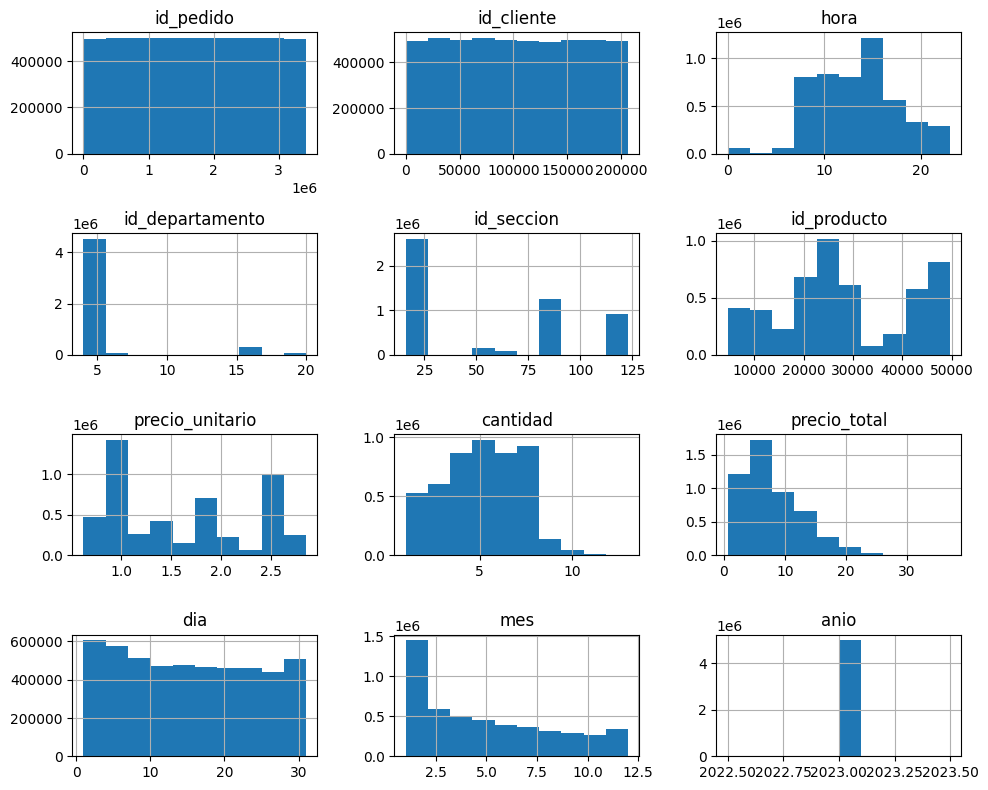

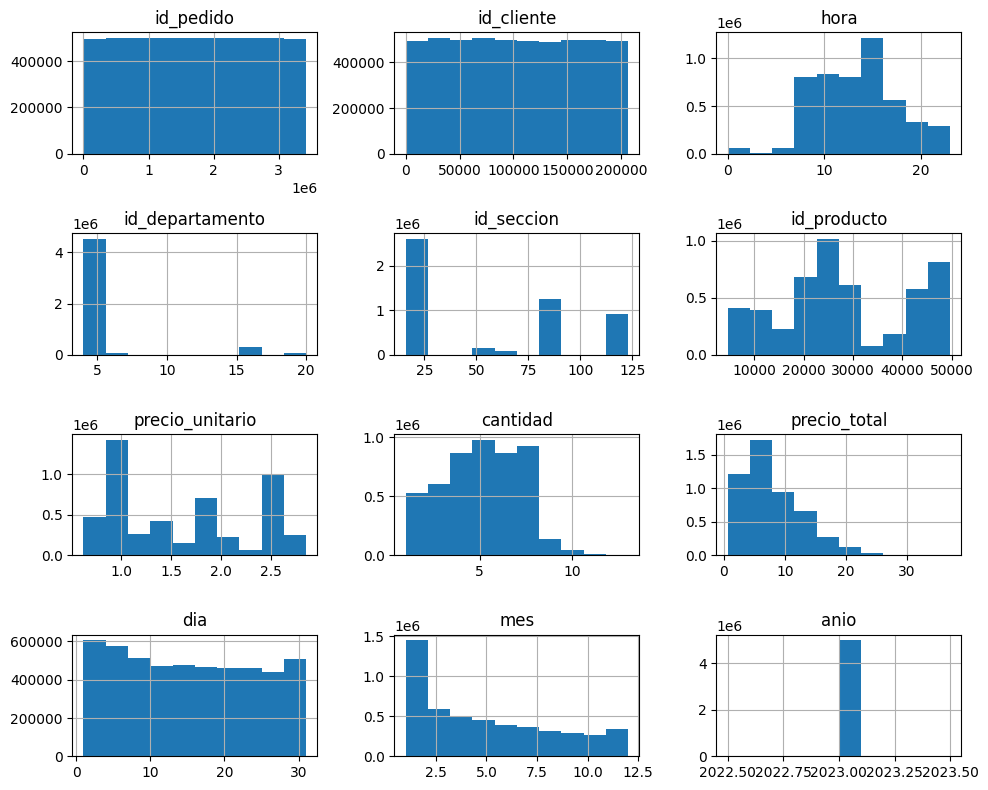

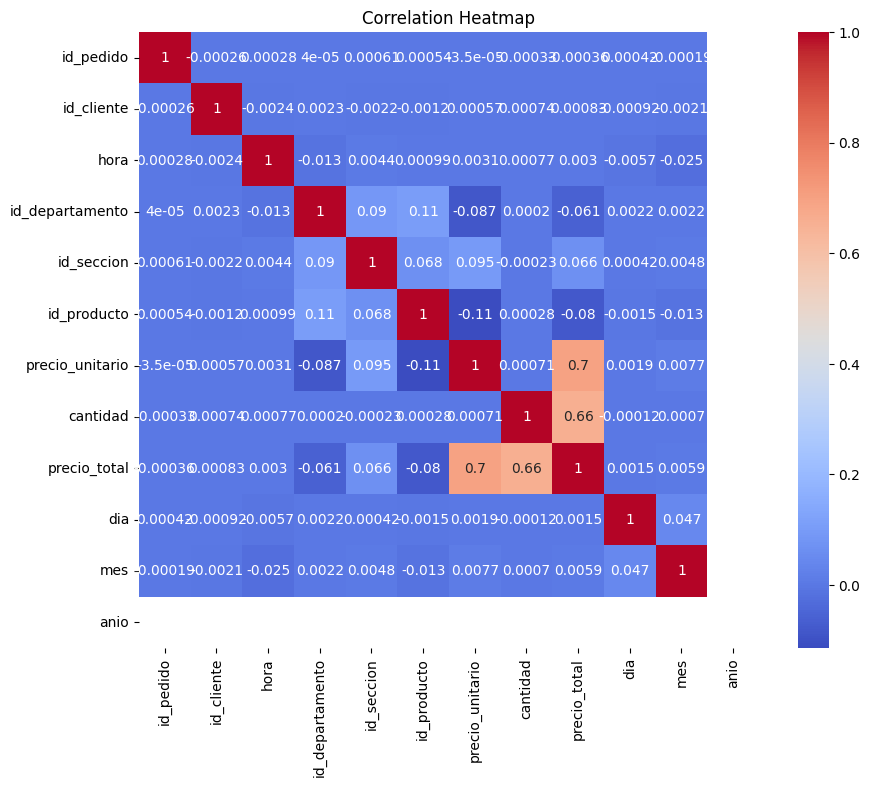

In [12]:
# Histograms for numerical columns
numerical_cols = df.select_dtypes(include=[np.number]).columns
df[numerical_cols].hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 8))
numerical_df = df.select_dtypes(include=[np.number])
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# Convertir Fecha/Hora

In [11]:
# Convertir 'fecha' a datetime
df['fecha'] = pd.to_datetime(df['fecha'])

# Generar nuevas columnas
df['dia'] = df['fecha'].dt.day
df['mes'] = df['fecha'].dt.month
df['anio'] = df['fecha'].dt.year
df['dia_semana'] = df['fecha'].dt.day_name()

# Crear datetime_compra combinando fecha y hora
df['datetime_compra'] = df['fecha'] + pd.to_timedelta(df['hora'], unit='h')

print("Conversión completada. Nuevas columnas agregadas.")
print(f"Columnas actuales: {list(df.columns)}")

# Mostrar primeras filas
display(df[['fecha', 'hora', 'dia', 'mes', 'anio', 'dia_semana', 'datetime_compra']].head())

Conversión completada. Nuevas columnas agregadas.
Columnas actuales: ['id_pedido', 'id_cliente', 'fecha', 'hora', 'id_departamento', 'id_seccion', 'id_producto', 'nombre_producto', 'precio_unitario', 'cantidad', 'precio_total', 'dia', 'mes', 'anio', 'dia_semana', 'datetime_compra']


Conversión completada. Nuevas columnas agregadas.
Columnas actuales: ['id_pedido', 'id_cliente', 'fecha', 'hora', 'id_departamento', 'id_seccion', 'id_producto', 'nombre_producto', 'precio_unitario', 'cantidad', 'precio_total', 'dia', 'mes', 'anio', 'dia_semana', 'datetime_compra']


,fecha,hora,dia,mes,anio,dia_semana,datetime_compra
0,2023-02-02,10,2,2,2023,Thursday,2023-02-02 10:00:00
1,2023-02-02,10,2,2,2023,Thursday,2023-02-02 10:00:00
2,2023-02-02,10,2,2,2023,Thursday,2023-02-02 10:00:00
3,2023-02-03,9,3,2,2023,Friday,2023-02-03 09:00:00
4,2023-02-03,9,3,2,2023,Friday,2023-02-03 09:00:00


# Validaciones Rápidas de Calidad de Datos

In [13]:
# 1. Verificar que precio_total ≈ precio_unitario * cantidad (con tolerancia por redondeo)
total_calculado = df['precio_unitario'] * df['cantidad']
tolerancia = 0.01  # Tolerancia para redondeo
inconsistencias_precio = ~np.isclose(df['precio_total'], total_calculado, atol=tolerancia)
print(f"Inconsistencias en precio_total (diferencia > {tolerancia}): {inconsistencias_precio.sum()}")

# 2. Verificar que cantidad > 0 y precio_unitario > 0
cantidad_invalida = (df['cantidad'] <= 0).sum()
precio_invalido = (df['precio_unitario'] <= 0).sum()
print(f"Cantidad <= 0: {cantidad_invalida}")
print(f"Precio_unitario <= 0: {precio_invalido}")

# 3. Duplicados exactos por (id_pedido, id_producto)
duplicados_por_claves = df.duplicated(subset=['id_pedido', 'id_producto']).sum()
print(f"Duplicados por (id_pedido, id_producto): {duplicados_por_claves}")

# Duplicados de fila completa
duplicados_fila_completa = df.duplicated().sum()
print(f"Duplicados de fila completa: {duplicados_fila_completa}")

Inconsistencias en precio_total (diferencia > 0.01): 0
Cantidad <= 0: 0
Precio_unitario <= 0: 0
Duplicados por (id_pedido, id_producto): 0
Duplicados de fila completa: 0


# Métricas Núcleo de Surtido por Producto

In [15]:
# Agrupar por id_producto para calcular métricas
metricas_producto = df.groupby('id_producto').agg(
    nombre_producto=('nombre_producto', 'first'),  # Etiqueta
    unidades_totales=('cantidad', 'sum'),
    pedidos_unicos=('id_pedido', 'nunique'),
    clientes_unicos=('id_cliente', 'nunique'),
    ingresos=('precio_total', 'sum')
).reset_index()

# Calcular métricas adicionales
metricas_producto['precio_promedio'] = metricas_producto['ingresos'] / metricas_producto['unidades_totales']
metricas_producto['ingreso_por_pedido'] = metricas_producto['ingresos'] / metricas_producto['pedidos_unicos']

# 2.3 Estabilidad: Ventas mensuales por producto
ventas_mensuales = df.groupby(['id_producto', 'mes']).agg(
    ingresos_mensuales=('precio_total', 'sum')
).reset_index()

# Para cada producto, calcular meses_activos y coeficiente de variación
estabilidad = ventas_mensuales.groupby('id_producto').agg(
    meses_activos=('ingresos_mensuales', lambda x: (x > 0).sum()),
    coef_variacion=('ingresos_mensuales', lambda x: x.std() / x.mean() if x.mean() > 0 else 0)
).reset_index()

# Unir con métricas principales
metricas_producto = metricas_producto.merge(estabilidad, on='id_producto', how='left')

# Mostrar las primeras filas de las métricas
print("Métricas por producto (primeras 10 filas):")
display(metricas_producto.head(10))

# CSV para análisis posterior
metricas_producto.to_csv('metricas_producto.csv', index=False)

Métricas por producto (primeras 10 filas):


,id_producto,nombre_producto,unidades_totales,pedidos_unicos,clientes_unicos,ingresos,precio_promedio,ingreso_por_pedido,meses_activos,coef_variacion
0,4605,Cebollas Amarillas,385227,76816,31101,327442.95,0.85,4.262692,12,0.649700
1,4920,Uvas Rojas sin Semillas,433605,86543,28685,1062332.25,2.45,12.275196,12,0.405859
2,5876,Limón Orgánico,456669,91107,28196,328801.68,0.72,3.608962,12,0.506323
3,8277,Manzana Honeycrisp Orgánica,437311,87171,23133,778413.58,1.78,8.929731,12,0.366519
4,8518,Cebolla Roja Orgánica,354939,70658,27031,326543.88,0.92,4.621471,12,0.373326
5,13176,Bolsa de Bananas Orgánicas,1976709,394108,65639,4842937.05,2.45,12.288350,12,0.391945
6,16797,Fresas,748065,149198,44838,1533533.25,2.05,10.278511,12,0.462611
7,17794,Zanahorias,377101,75143,27013,358245.95,0.95,4.767523,12,0.544331
8,19057,Manzana Fuji Extra Grande Orgánica,389869,77879,18558,709561.58,1.82,9.111077,12,0.370287
9,21137,Fresas Orgánicas,1381309,275018,61114,3439459.41,2.49,12.506307,12,0.589636


# Rankings Ejecutivos - Top 15

In [17]:
# Columnas a incluir en los rankings
columnas_ranking = ['nombre_producto', 'ingresos', 'unidades_totales', 'pedidos_unicos', 'clientes_unicos', 'precio_promedio']

# Top 15 por ingresos
top_ingresos = metricas_producto.sort_values('ingresos', ascending=False).head(15)[columnas_ranking]
print("Top 15 productos por ingresos:")
display(top_ingresos)

# Top 15 por unidades
top_unidades = metricas_producto.sort_values('unidades_totales', ascending=False).head(15)[columnas_ranking]
print("\nTop 15 productos por unidades vendidas:")
display(top_unidades)

# Top 15 por pedidos únicos (frecuencia)
top_pedidos = metricas_producto.sort_values('pedidos_unicos', ascending=False).head(15)[columnas_ranking]
print("\nTop 15 productos por pedidos únicos (frecuencia):")
display(top_pedidos)

# Insights ejecutivos más descriptivos
print("\nInsights:")
print("- Productos premium: altos ingresos con baja frecuencia de pedidos. Estos productos generan mucho valor económico pero son comprados por pocos clientes, ideal para estrategias de upsell o nichos de lujo. Ejemplo: productos de alta gama que aumentan el ticket promedio.")
print("- Productos de tráfico: alta frecuencia que sostiene el flujo de clientes. Son esenciales para atraer y retener compradores diarios, contribuyendo al volumen total de ventas y fidelización. Ejemplo: artículos básicos que impulsan visitas recurrentes.")
print("- Estrategia recomendada: Combinar ambos tipos para maximizar ingresos y tráfico. Monitorear la estabilidad mensual para evitar dependencias de picos estacionales y asegurar un surtido equilibrado.")

Top 15 productos por ingresos:


,nombre_producto,ingresos,unidades_totales,pedidos_unicos,clientes_unicos,precio_promedio
5,Bolsa de Bananas Orgánicas,4842937.05,1976709,394108,65639,2.45
9,Fresas Orgánicas,3439459.41,1381309,275018,61114,2.49
13,Banana,2583340.20,2460324,490518,76114,1.05
19,Frambuesas Orgánicas,2032919.25,713305,142293,32901,2.85
35,Aguacate Hass Orgánico,1977873.03,1104957,220502,44700,1.79
11,Espinacas Baby Orgánicas,1874911.70,1258330,251321,56754,1.49
37,Aguacate Orgánico,1616056.75,923461,183961,43947,1.75
6,Fresas,1533533.25,748065,149198,44838,2.05
26,Arándanos Orgánicos,1444778.50,525374,104784,38702,2.75
27,Tomates Cherry Orgánicos,1128040.95,442369,87904,30109,2.55



Top 15 productos por unidades vendidas:


,nombre_producto,ingresos,unidades_totales,pedidos_unicos,clientes_unicos,precio_promedio
13,Banana,2583340.20,2460324,490518,76114,1.05
5,Bolsa de Bananas Orgánicas,4842937.05,1976709,394108,65639,2.45
9,Fresas Orgánicas,3439459.41,1381309,275018,61114,2.49
11,Espinacas Baby Orgánicas,1874911.70,1258330,251321,56754,1.49
35,Aguacate Hass Orgánico,1977873.03,1104957,220502,44700,1.79
37,Aguacate Orgánico,1616056.75,923461,183961,43947,1.75
36,Limón Grande,498946.24,804752,160515,48592,0.62
6,Fresas,1533533.25,748065,149198,44838,2.05
15,Limones,498940.48,733736,146437,46636,0.68
18,Leche Entera Orgánica,707934.15,715085,142530,24128,0.99



Top 15 productos por pedidos únicos (frecuencia):


,nombre_producto,ingresos,unidades_totales,pedidos_unicos,clientes_unicos,precio_promedio
13,Banana,2583340.20,2460324,490518,76114,1.05
5,Bolsa de Bananas Orgánicas,4842937.05,1976709,394108,65639,2.45
9,Fresas Orgánicas,3439459.41,1381309,275018,61114,2.49
11,Espinacas Baby Orgánicas,1874911.70,1258330,251321,56754,1.49
35,Aguacate Hass Orgánico,1977873.03,1104957,220502,44700,1.79
37,Aguacate Orgánico,1616056.75,923461,183961,43947,1.75
36,Limón Grande,498946.24,804752,160515,48592,0.62
6,Fresas,1533533.25,748065,149198,44838,2.05
15,Limones,498940.48,733736,146437,46636,0.68
18,Leche Entera Orgánica,707934.15,715085,142530,24128,0.99



Insights:
- Productos premium: altos ingresos con baja frecuencia de pedidos. Estos productos generan mucho valor económico pero son comprados por pocos clientes, ideal para estrategias de upsell o nichos de lujo. Ejemplo: productos de alta gama que aumentan el ticket promedio.
- Productos de tráfico: alta frecuencia que sostiene el flujo de clientes. Son esenciales para atraer y retener compradores diarios, contribuyendo al volumen total de ventas y fidelización. Ejemplo: artículos básicos que impulsan visitas recurrentes.
- Estrategia recomendada: Combinar ambos tipos para maximizar ingresos y tráfico. Monitorear la estabilidad mensual para evitar dependencias de picos estacionales y asegurar un surtido equilibrado.


# Análisis Pareto / ABC

In [19]:
# ABC por ingresos
abc_ingresos = metricas_producto.sort_values('ingresos', ascending=False).copy()
total_ingresos = abc_ingresos['ingresos'].sum()
abc_ingresos['%_ingresos'] = (abc_ingresos['ingresos'] / total_ingresos) * 100
abc_ingresos['%_acumulado'] = abc_ingresos['%_ingresos'].cumsum()

def clasificar_abc(acumulado):
    if acumulado <= 80:
        return 'A'
    elif acumulado <= 95:
        return 'B'
    else:
        return 'C'

abc_ingresos['categoria_abc'] = abc_ingresos['%_acumulado'].apply(clasificar_abc)

print("ABC por ingresos:")
display(abc_ingresos[['nombre_producto', 'ingresos', '%_ingresos', '%_acumulado', 'categoria_abc']].head(50))

# ABC por unidades
abc_unidades = metricas_producto.sort_values('unidades_totales', ascending=False).copy()
total_unidades = abc_unidades['unidades_totales'].sum()
abc_unidades['%_unidades'] = (abc_unidades['unidades_totales'] / total_unidades) * 100
abc_unidades['%_acumulado'] = abc_unidades['%_unidades'].cumsum()
abc_unidades['categoria_abc'] = abc_unidades['%_acumulado'].apply(clasificar_abc)

print("\nABC por unidades:")
display(abc_unidades[['nombre_producto', 'unidades_totales', '%_unidades', '%_acumulado', 'categoria_abc']].head(50))

# Insights clave
print("\nInsights del Análisis ABC:")
print("1. Productos A por ingresos: Son los que 'pagan la cuenta'. Representan el 20% de productos que generan el 80% de los ingresos. Enfocarse en mantener y promocionar estos para asegurar rentabilidad.")
print("2. Productos A por unidades: Son los que 'mueven la operación'. El 20% de productos que representan el 80% de las unidades vendidas. Esenciales para el flujo diario y logística.")
print("3. Productos C: Muchos productos C explican poco ingreso pero consumen complejidad operativa. Evaluar si vale la pena mantenerlos en stock, ya que aumentan costos sin contribuir significativamente a ingresos.")
print("4. Desalineación A ingresos vs A unidades: Si los productos A por ingresos no coinciden con A por unidades, indica oportunidades para cross-selling o ajustes en precios/estrategias de venta.")
print("5. Estrategia recomendada: Optimizar el surtido priorizando productos A, racionalizando productos C y usando productos B como complemento. Monitorear cambios en categorías ABC para adaptarse a tendencias.")

ABC por ingresos:


,nombre_producto,ingresos,%_ingresos,%_acumulado,categoria_abc
5,Bolsa de Bananas Orgánicas,4842937.05,12.151429,12.151429,A
9,Fresas Orgánicas,3439459.41,8.629959,20.781388,A
13,Banana,2583340.20,6.481867,27.263256,A
19,Frambuesas Orgánicas,2032919.25,5.100804,32.364060,A
35,Aguacate Hass Orgánico,1977873.03,4.962688,37.326748,A
11,Espinacas Baby Orgánicas,1874911.70,4.704347,42.031095,A
37,Aguacate Orgánico,1616056.75,4.054853,46.085949,A
6,Fresas,1533533.25,3.847793,49.933742,A
26,Arándanos Orgánicos,1444778.50,3.625099,53.558841,A
27,Tomates Cherry Orgánicos,1128040.95,2.830371,56.389212,A



ABC por unidades:


,nombre_producto,unidades_totales,%_unidades,%_acumulado,categoria_abc
13,Banana,2460324,9.859338,9.859338,A
5,Bolsa de Bananas Orgánicas,1976709,7.921331,17.780669,A
9,Fresas Orgánicas,1381309,5.535365,23.316034,A
11,Espinacas Baby Orgánicas,1258330,5.042547,28.358582,A
35,Aguacate Hass Orgánico,1104957,4.427931,32.786513,A
37,Aguacate Orgánico,923461,3.700616,36.487129,A
36,Limón Grande,804752,3.224909,39.712038,A
6,Fresas,748065,2.997746,42.709783,A
15,Limones,733736,2.940325,45.650108,A
18,Leche Entera Orgánica,715085,2.865584,48.515692,A



Insights del Análisis ABC:
1. Productos A por ingresos: Son los que 'pagan la cuenta'. Representan el 20% de productos que generan el 80% de los ingresos. Enfocarse en mantener y promocionar estos para asegurar rentabilidad.
2. Productos A por unidades: Son los que 'mueven la operación'. El 20% de productos que representan el 80% de las unidades vendidas. Esenciales para el flujo diario y logística.
3. Productos C: Muchos productos C explican poco ingreso pero consumen complejidad operativa. Evaluar si vale la pena mantenerlos en stock, ya que aumentan costos sin contribuir significativamente a ingresos.
4. Desalineación A ingresos vs A unidades: Si los productos A por ingresos no coinciden con A por unidades, indica oportunidades para cross-selling o ajustes en precios/estrategias de venta.
5. Estrategia recomendada: Optimizar el surtido priorizando productos A, racionalizando productos C y usando productos B como complemento. Monitorear cambios en categorías ABC para adaptarse a ten

# Segmentación 2×2 (Ingresos vs Rotación)

Mediana pedidos únicos: 86857.0
Mediana ingresos: 670715.37


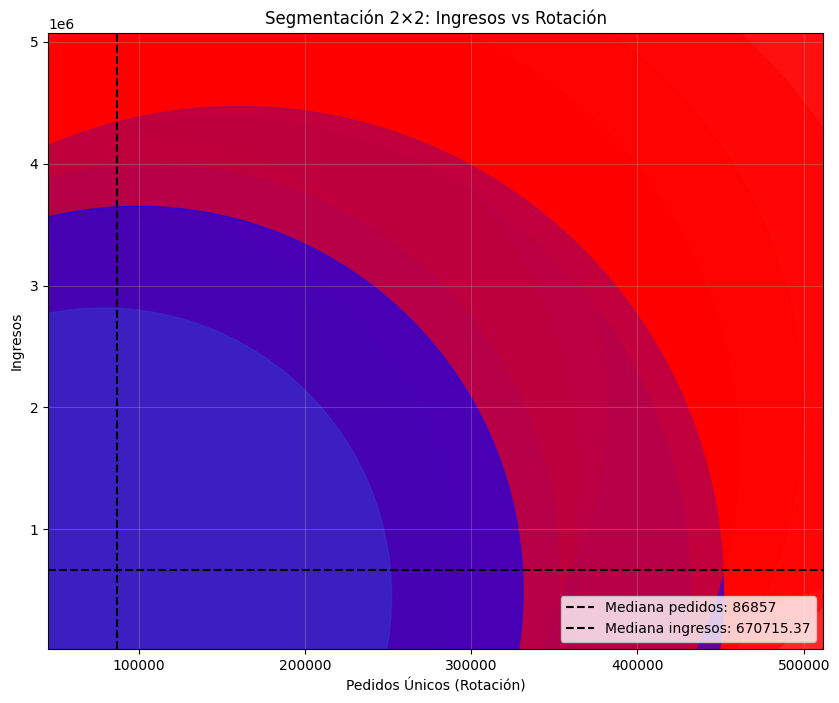


Conteo por cuadrante:
cuadrante
Long Tail Weak      13
Core Stars          13
Nicho Premium        7
Traffic Builders     7
Name: count, dtype: int64

Acciones recomendadas por cuadrante:
- Core Stars (Alta rotación / Alto ingreso): Mantener + asegurar stock + destacar en promociones.
- Traffic Builders (Alta rotación / Bajo ingreso): Mantener + mejorar margen (packs, pricing, cross-sell).
- Nicho Premium (Baja rotación / Alto ingreso): Mantener selectivo + controlar inventario + disponibilidad limitada.
- Long Tail Weak (Baja rotación / Bajo ingreso): Candidatos a depurar o reemplazar. Evaluar eliminación o sustitución.

Ejemplos de Core Stars:


,nombre_producto,ingresos,pedidos_unicos
3,Manzana Honeycrisp Orgánica,778413.58,87171
5,Bolsa de Bananas Orgánicas,4842937.05,394108
6,Fresas,1533533.25,149198
9,Fresas Orgánicas,3439459.41,275018
11,Espinacas Baby Orgánicas,1874911.70,251321
13,Banana,2583340.20,490518
18,Leche Entera Orgánica,707934.15,142530
19,Frambuesas Orgánicas,2032919.25,142293
20,Manzana Fuji Orgánica,673307.50,92767
26,Arándanos Orgánicos,1444778.50,104784



Ejemplos de Traffic Builders:


,nombre_producto,ingresos,pedidos_unicos
2,Limón Orgánico,328801.68,91107
12,Cebolla Amarilla Orgánica,518325.28,117561
14,Ajo Orgánico,558954.76,113759
15,Limones,498940.48,146437
32,Calabacín Orgánico,668123.24,109240
36,Limón Grande,498946.24,160515
39,Pepino Kirby,495032.67,99714



Ejemplos de Nicho Premium:


,nombre_producto,ingresos,pedidos_unicos
1,Uvas Rojas sin Semillas,1062332.25,86543
8,Manzana Fuji Extra Grande Orgánica,709561.58,77879
21,Col Rizada Orgánica de Michigan,895710.45,69977
23,Hummus Original,946220.85,74039
25,Manzanas Gala Orgánicas,750356.64,75515
28,Racimo de Tomates Orgánicos,753390.00,66735
34,Espárragos,694759.65,71009



Ejemplos de Long Tail Weak:


,nombre_producto,ingresos,pedidos_unicos
0,Cebollas Amarillas,327442.95,76816
4,Cebolla Roja Orgánica,326543.88,70658
7,Zanahorias,358245.95,75143
10,Rúcula Baby Orgánica,588347.45,75647
16,Crema,366961.32,71501
17,Coliflor Fresca,548939.40,74123
22,Pepino Orgánico,433966.14,84758
24,Cilantro Orgánico,251740.29,72908
29,Zanahorias Baby Orgánicas,503493.75,80317
30,Apio Orgánico en Ramillete Pequeño,657878.50,70621


In [21]:
# Calcular medianas para cortes
mediana_pedidos = metricas_producto['pedidos_unicos'].median()
mediana_ingresos = metricas_producto['ingresos'].median()

print(f"Mediana pedidos únicos: {mediana_pedidos}")
print(f"Mediana ingresos: {mediana_ingresos}")

# Clasificar cuadrantes
def clasificar_cuadrante(row):
    alta_rotacion = row['pedidos_unicos'] >= mediana_pedidos
    alto_ingreso = row['ingresos'] >= mediana_ingresos
    
    if alta_rotacion and alto_ingreso:
        return 'Core Stars'
    elif alta_rotacion and not alto_ingreso:
        return 'Traffic Builders'
    elif not alta_rotacion and alto_ingreso:
        return 'Nicho Premium'
    else:
        return 'Long Tail Weak'

metricas_producto['cuadrante'] = metricas_producto.apply(clasificar_cuadrante, axis=1)

# Scatter plot con cuadrantes
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    metricas_producto['pedidos_unicos'], 
    metricas_producto['ingresos'], 
    s=metricas_producto['clientes_unicos'] * 10,  # Tamaño proporcional a clientes únicos
    c=metricas_producto['cuadrante'].map({'Core Stars': 'red', 'Traffic Builders': 'blue', 'Nicho Premium': 'green', 'Long Tail Weak': 'gray'}),
    alpha=0.6
)

# Líneas de corte
plt.axvline(x=mediana_pedidos, color='black', linestyle='--', label=f'Mediana pedidos: {mediana_pedidos:.0f}')
plt.axhline(y=mediana_ingresos, color='black', linestyle='--', label=f'Mediana ingresos: {mediana_ingresos:.2f}')

# Etiquetas
plt.xlabel('Pedidos Únicos (Rotación)')
plt.ylabel('Ingresos')
plt.title('Segmentación 2×2: Ingresos vs Rotación')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Conteo por cuadrante
conteo_cuadrantes = metricas_producto['cuadrante'].value_counts()
print("\nConteo por cuadrante:")
print(conteo_cuadrantes)

# Acciones recomendadas
print("\nAcciones recomendadas por cuadrante:")
print("- Core Stars (Alta rotación / Alto ingreso): Mantener + asegurar stock + destacar en promociones.")
print("- Traffic Builders (Alta rotación / Bajo ingreso): Mantener + mejorar margen (packs, pricing, cross-sell).")
print("- Nicho Premium (Baja rotación / Alto ingreso): Mantener selectivo + controlar inventario + disponibilidad limitada.")
print("- Long Tail Weak (Baja rotación / Bajo ingreso): Candidatos a depurar o reemplazar. Evaluar eliminación o sustitución.")

# Mostrar ejemplos por cuadrante
for cuadrante in ['Core Stars', 'Traffic Builders', 'Nicho Premium', 'Long Tail Weak']:
    ejemplos = metricas_producto[metricas_producto['cuadrante'] == cuadrante].head(10)[['nombre_producto', 'ingresos', 'pedidos_unicos']]
    print(f"\nEjemplos de {cuadrante}:")
    display(ejemplos)

# Orgánico vs No Orgánico - Feature Engineering

In [22]:
# Crear feature es_organico
metricas_producto['es_organico'] = metricas_producto['nombre_producto'].str.contains('Orgánic|Orgánico', case=False, na=False).astype(int)

# Conteo de orgánicos vs no orgánicos
conteo_tipo = metricas_producto['es_organico'].value_counts()
print("Conteo de productos:")
print(f"Orgánicos: {conteo_tipo.get(1, 0)}")
print(f"No orgánicos: {conteo_tipo.get(0, 0)}")

# 6.2 Comparaciones
# Participación en ingresos, unidades, pedidos
total_ingresos = metricas_producto['ingresos'].sum()
total_unidades = metricas_producto['unidades_totales'].sum()
total_pedidos = metricas_producto['pedidos_unicos'].sum()

participacion_organicos = metricas_producto[metricas_producto['es_organico'] == 1][['ingresos', 'unidades_totales', 'pedidos_unicos']].sum()
participacion_no_organicos = metricas_producto[metricas_producto['es_organico'] == 0][['ingresos', 'unidades_totales', 'pedidos_unicos']].sum()

print("\nParticipación de orgánicos:")
print(f"Ingresos: {participacion_organicos['ingresos'] / total_ingresos * 100:.1f}%")
print(f"Unidades: {participacion_organicos['unidades_totales'] / total_unidades * 100:.1f}%")
print(f"Pedidos: {participacion_organicos['pedidos_unicos'] / total_pedidos * 100:.1f}%")

# Top orgánicos vs top no orgánicos
top_organicos = metricas_producto[metricas_producto['es_organico'] == 1].sort_values('ingresos', ascending=False).head(5)[['nombre_producto', 'ingresos']]
top_no_organicos = metricas_producto[metricas_producto['es_organico'] == 0].sort_values('ingresos', ascending=False).head(5)[['nombre_producto', 'ingresos']]

print("\nTop 5 orgánicos por ingresos:")
display(top_organicos)

print("\nTop 5 no orgánicos por ingresos:")
display(top_no_organicos)

# Precio promedio orgánico vs no orgánico
precio_promedio_organico = metricas_producto[metricas_producto['es_organico'] == 1]['precio_promedio'].mean()
precio_promedio_no_organico = metricas_producto[metricas_producto['es_organico'] == 0]['precio_promedio'].mean()

print(f"\nPrecio promedio orgánico: {precio_promedio_organico:.2f}")
print(f"Precio promedio no orgánico: {precio_promedio_no_organico:.2f}")
print(f"Diferencia: {precio_promedio_organico - precio_promedio_no_organico:.2f} ({(precio_promedio_organico / precio_promedio_no_organico - 1) * 100:.1f}%)")

# Conclusión típica
print("\nConclusión:")
print("Los productos orgánicos suelen tener mayor precio promedio, lo que refleja su valor premium. Sin embargo, pueden tener menor rotación, lo que afecta la gestión de stock y el surtido. Es importante equilibrar la oferta para maximizar ingresos sin sobrecargar inventario.")

Conteo de productos:
Orgánicos: 26
No orgánicos: 14

Participación de orgánicos:
Ingresos: 72.6%
Unidades: 65.1%
Pedidos: 65.1%

Top 5 orgánicos por ingresos:


,nombre_producto,ingresos
5,Bolsa de Bananas Orgánicas,4842937.05
9,Fresas Orgánicas,3439459.41
19,Frambuesas Orgánicas,2032919.25
35,Aguacate Hass Orgánico,1977873.03
11,Espinacas Baby Orgánicas,1874911.70



Top 5 no orgánicos por ingresos:


,nombre_producto,ingresos
13,Banana,2583340.20
6,Fresas,1533533.25
1,Uvas Rojas sin Semillas,1062332.25
23,Hummus Original,946220.85
34,Espárragos,694759.65



Precio promedio orgánico: 1.66
Precio promedio no orgánico: 1.37
Diferencia: 0.29 (21.4%)

Conclusión:
Los productos orgánicos suelen tener mayor precio promedio, lo que refleja su valor premium. Sin embargo, pueden tener menor rotación, lo que afecta la gestión de stock y el surtido. Es importante equilibrar la oferta para maximizar ingresos sin sobrecargar inventario.


# Recomendación final para Negocio

In [25]:
# 7.1 Tabla final por producto
# Unir ABC ingresos y unidades con cuadrante y es_organico
abc_ingresos_simple = abc_ingresos[['id_producto', 'categoria_abc']].rename(columns={'categoria_abc': 'clase_ABC_ingresos'})
abc_unidades_simple = abc_unidades[['id_producto', 'categoria_abc']].rename(columns={'categoria_abc': 'clase_ABC_unidades'})

tabla_final = metricas_producto[['id_producto', 'nombre_producto', 'ingresos', 'unidades_totales', 'pedidos_unicos', 'clientes_unicos', 'cuadrante', 'es_organico']].merge(
    abc_ingresos_simple, on='id_producto', how='left'
).merge(
    abc_unidades_simple, on='id_producto', how='left'
).rename(columns={'cuadrante': 'cuadrante_2x2'})

print("Tabla final por producto (primeras 10 filas):")
display(tabla_final.head(10))

# 7.2 Reglas de decisión
def definir_accion(row):
    abc_ing = row['clase_ABC_ingresos']
    abc_uni = row['clase_ABC_unidades']
    cuadrante = row['cuadrante_2x2']
    pedidos = row['pedidos_unicos']
    ingresos = row['ingresos']
    mediana_pedidos = metricas_producto['pedidos_unicos'].median()
    mediana_ingresos = metricas_producto['ingresos'].median()
    
    # Mantener / Expandir: A en ingresos o en unidades + cuadrante Star
    if (abc_ing == 'A' or abc_uni == 'A') and cuadrante == 'Core Stars':
        return 'Mantener / Expandir'
    # Optimizar (precio/promos): Alta rotación + bajo ingreso
    elif pedidos >= mediana_pedidos and ingresos < mediana_ingresos:
        return 'Optimizar (precio/promos)'
    # Mantener selectivo: Alto ingreso + baja rotación
    elif ingresos >= mediana_ingresos and pedidos < mediana_pedidos:
        return 'Mantener selectivo'
    # Depurar / revisar: C en ingresos y C en unidades + baja rotación
    elif abc_ing == 'C' and abc_uni == 'C' and pedidos < mediana_pedidos:
        return 'Depurar / revisar'
    else:
        return 'Monitorear'

tabla_final['accion_recomendada'] = tabla_final.apply(definir_accion, axis=1)

print("\nTabla con acciones recomendadas (primeras 10 filas):")
display(tabla_final[['nombre_producto', 'clase_ABC_ingresos', 'clase_ABC_unidades', 'cuadrante_2x2', 'accion_recomendada']].head(10))

# 7.3 Resultados presentables
# Lista de 10 productos para expandir
expandir = tabla_final[tabla_final['accion_recomendada'] == 'Mantener / Expandir'].sort_values('ingresos', ascending=False).head(10)[['nombre_producto', 'ingresos', 'unidades_totales']]
print("\nLista de 10 productos para expandir:")
display(expandir)

# Lista de 10 productos para revisar (long tail)
revisar = tabla_final[tabla_final['accion_recomendada'] == 'Depurar / revisar'].sort_values('ingresos', ascending=True).head(10)[['nombre_producto', 'ingresos', 'unidades_totales']]
print("\nLista de 10 productos para revisar (long tail):")
display(revisar)

# Productos orgánicos con mejor performance (top por ingresos)
organicos_top = tabla_final[tabla_final['es_organico'] == 1].sort_values('ingresos', ascending=False).head(10)[['nombre_producto', 'ingresos', 'unidades_totales', 'pedidos_unicos']]
print("\nProductos orgánicos con mejor performance:")
display(organicos_top)

# Guardar tabla final
tabla_final.to_csv('recomendaciones_finales.csv', index=False)


Tabla final por producto (primeras 10 filas):


,id_producto,nombre_producto,ingresos,unidades_totales,pedidos_unicos,clientes_unicos,cuadrante_2x2,es_organico,clase_ABC_ingresos,clase_ABC_unidades
0,4605,Cebollas Amarillas,327442.95,385227,76816,31101,Long Tail Weak,0,C,B
1,4920,Uvas Rojas sin Semillas,1062332.25,433605,86543,28685,Nicho Premium,0,A,A
2,5876,Limón Orgánico,328801.68,456669,91107,28196,Traffic Builders,1,C,A
3,8277,Manzana Honeycrisp Orgánica,778413.58,437311,87171,23133,Core Stars,1,A,A
4,8518,Cebolla Roja Orgánica,326543.88,354939,70658,27031,Long Tail Weak,1,C,C
5,13176,Bolsa de Bananas Orgánicas,4842937.05,1976709,394108,65639,Core Stars,1,A,A
6,16797,Fresas,1533533.25,748065,149198,44838,Core Stars,0,A,A
7,17794,Zanahorias,358245.95,377101,75143,27013,Long Tail Weak,0,C,B
8,19057,Manzana Fuji Extra Grande Orgánica,709561.58,389869,77879,18558,Nicho Premium,1,A,B
9,21137,Fresas Orgánicas,3439459.41,1381309,275018,61114,Core Stars,1,A,A



Tabla con acciones recomendadas (primeras 10 filas):


,nombre_producto,clase_ABC_ingresos,clase_ABC_unidades,cuadrante_2x2,accion_recomendada
0,Cebollas Amarillas,C,B,Long Tail Weak,Monitorear
1,Uvas Rojas sin Semillas,A,A,Nicho Premium,Mantener selectivo
2,Limón Orgánico,C,A,Traffic Builders,Optimizar (precio/promos)
3,Manzana Honeycrisp Orgánica,A,A,Core Stars,Mantener / Expandir
4,Cebolla Roja Orgánica,C,C,Long Tail Weak,Depurar / revisar
5,Bolsa de Bananas Orgánicas,A,A,Core Stars,Mantener / Expandir
6,Fresas,A,A,Core Stars,Mantener / Expandir
7,Zanahorias,C,B,Long Tail Weak,Monitorear
8,Manzana Fuji Extra Grande Orgánica,A,B,Nicho Premium,Mantener selectivo
9,Fresas Orgánicas,A,A,Core Stars,Mantener / Expandir



Lista de 10 productos para expandir:


,nombre_producto,ingresos,unidades_totales
5,Bolsa de Bananas Orgánicas,4842937.05,1976709
9,Fresas Orgánicas,3439459.41,1381309
13,Banana,2583340.20,2460324
19,Frambuesas Orgánicas,2032919.25,713305
35,Aguacate Hass Orgánico,1977873.03,1104957
11,Espinacas Baby Orgánicas,1874911.70,1258330
37,Aguacate Orgánico,1616056.75,923461
6,Fresas,1533533.25,748065
26,Arándanos Orgánicos,1444778.50,525374
27,Tomates Cherry Orgánicos,1128040.95,442369



Lista de 10 productos para revisar (long tail):


,nombre_producto,ingresos,unidades_totales
4,Cebolla Roja Orgánica,326543.88,354939



Productos orgánicos con mejor performance:


,nombre_producto,ingresos,unidades_totales,pedidos_unicos
5,Bolsa de Bananas Orgánicas,4842937.05,1976709,394108
9,Fresas Orgánicas,3439459.41,1381309,275018
19,Frambuesas Orgánicas,2032919.25,713305,142293
35,Aguacate Hass Orgánico,1977873.03,1104957,220502
11,Espinacas Baby Orgánicas,1874911.70,1258330,251321
37,Aguacate Orgánico,1616056.75,923461,183961
26,Arándanos Orgánicos,1444778.50,525374,104784
27,Tomates Cherry Orgánicos,1128040.95,442369,87904
21,Col Rizada Orgánica de Michigan,895710.45,351259,69977
3,Manzana Honeycrisp Orgánica,778413.58,437311,87171


# Visualizaciones Claves

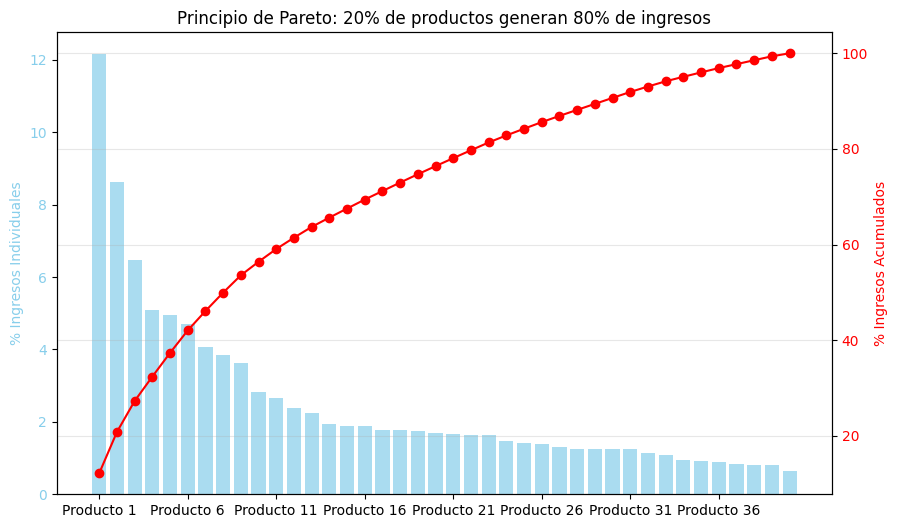

Interpretación: Los primeros productos concentran la mayoría de los ingresos, confirmando el principio 80/20 y priorizando el surtido A.


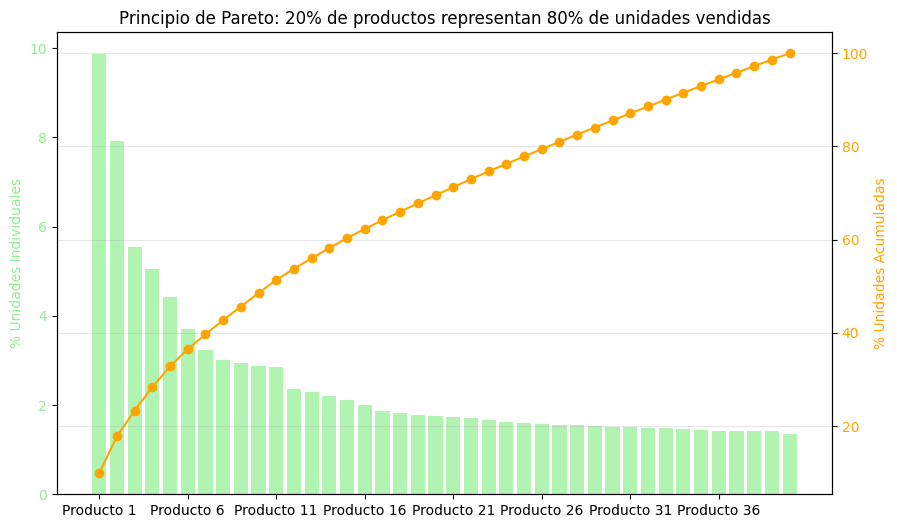

Interpretación: Pocos productos mueven el volumen operativo; alinear ABC ingresos y unidades para optimizar logística.


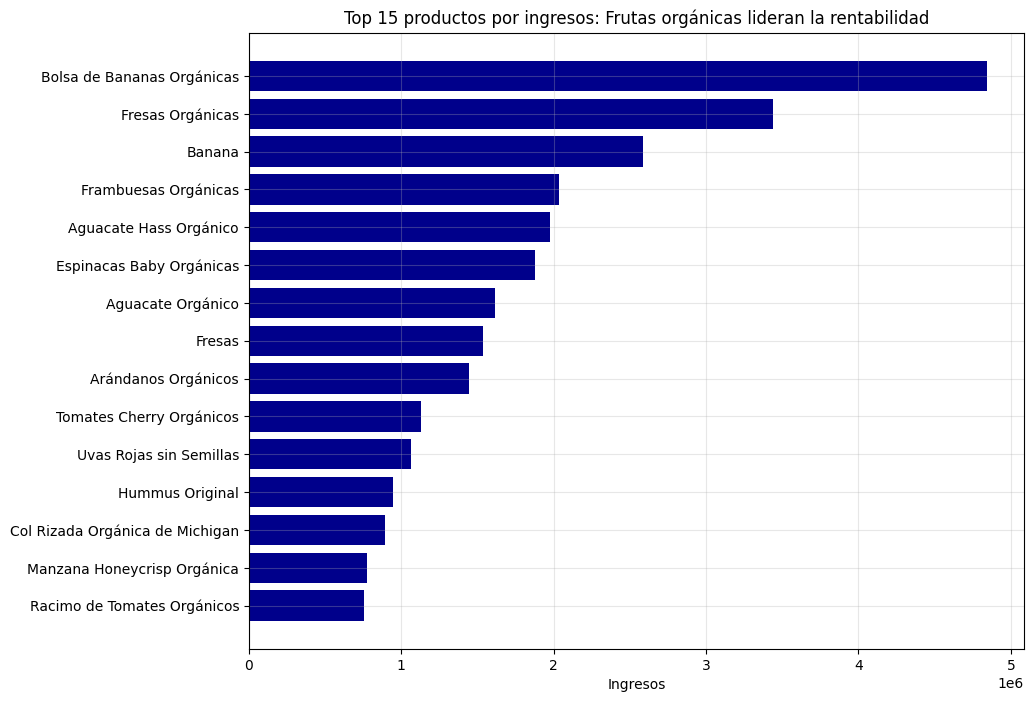

Interpretación: Productos premium como bananas y fresas orgánicas dominan; invertir en promoción y stock para maximizar ROI.


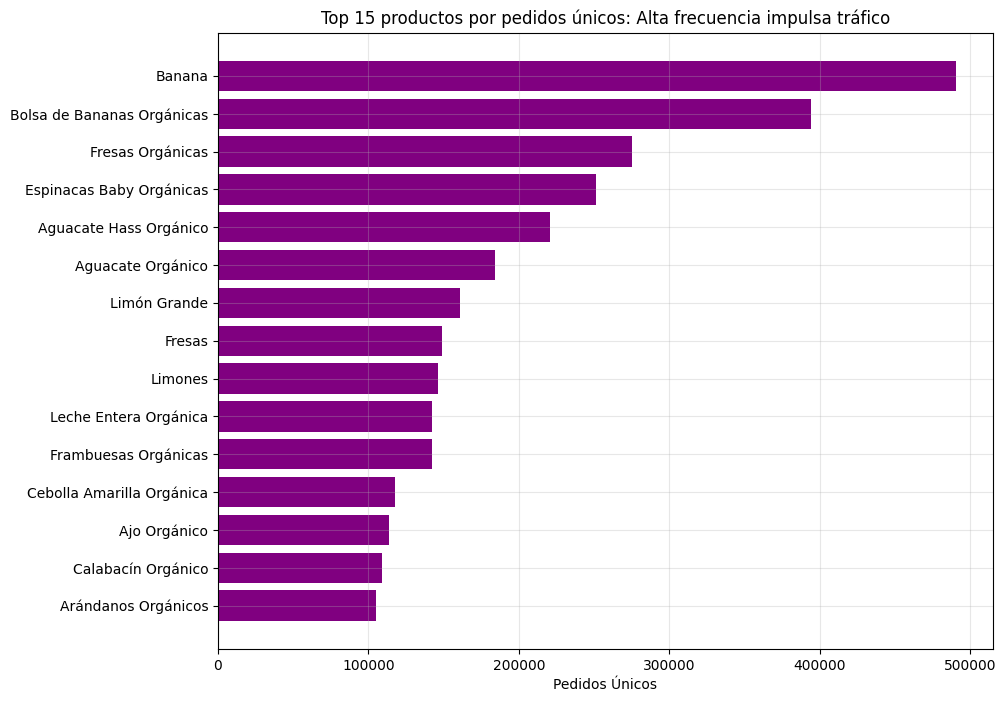

Interpretación: Productos de alto tráfico como bananas sostienen visitas recurrentes; esenciales para fidelización y cross-selling.


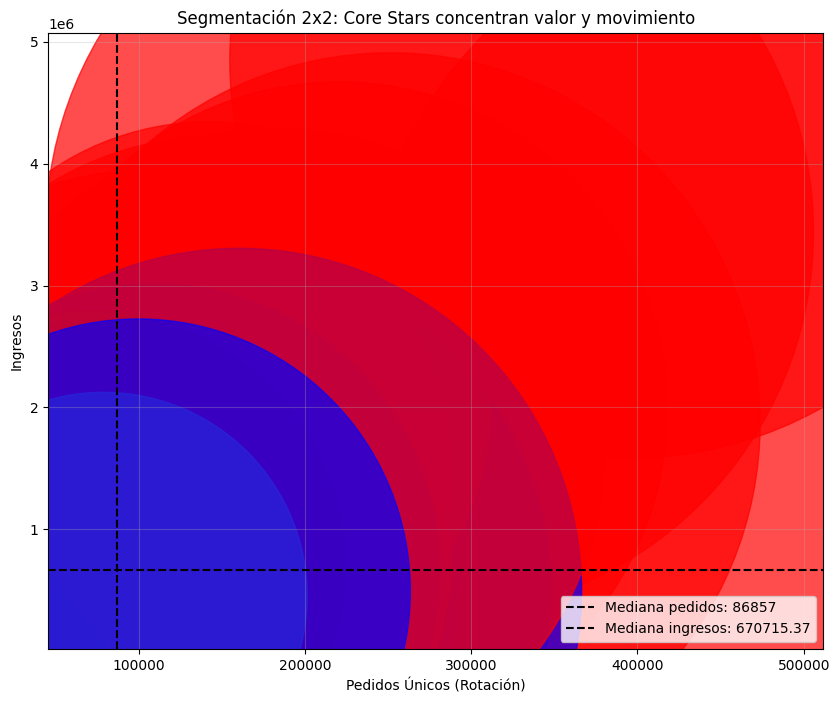

Interpretación: Core Stars son pilares del negocio; Long Tail Weak requieren evaluación para racionalizar surtido.


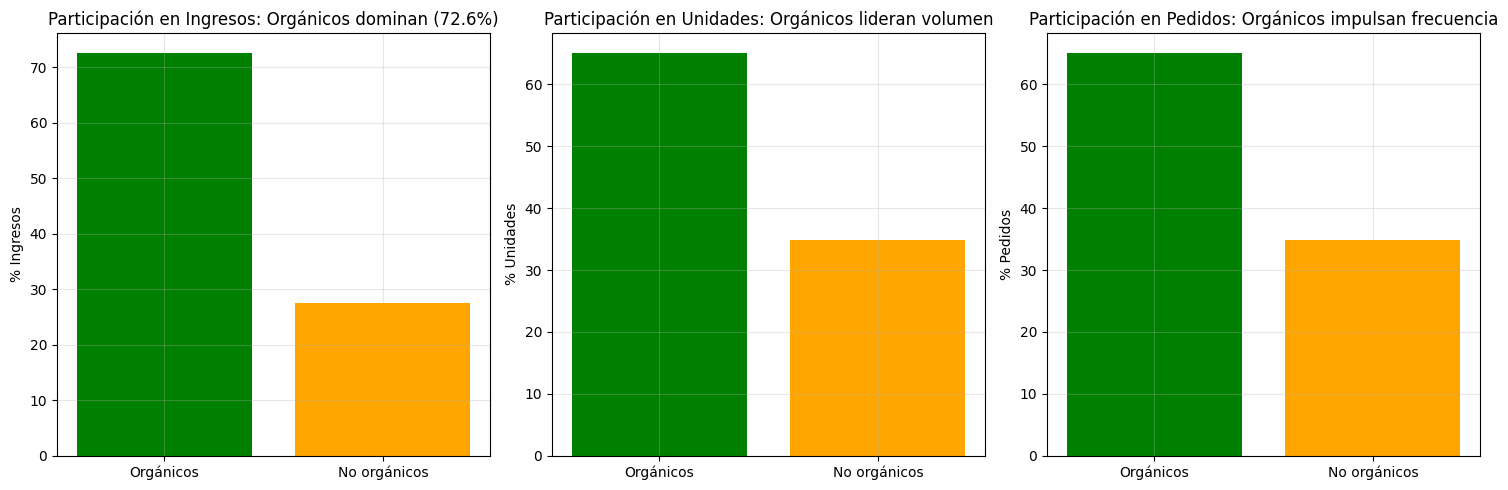

Interpretación: Orgánicos generan más valor en todas las métricas; equilibrar oferta para capitalizar premium sin descuidar no orgánicos.


In [26]:
# Visualizaciones claves

# 1. Pareto ingresos
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.bar(range(len(abc_ingresos)), abc_ingresos['%_ingresos'], color='skyblue', alpha=0.7, label='% Individual')
ax1.set_ylabel('% Ingresos Individuales', color='skyblue')
ax1.tick_params(axis='y', labelcolor='skyblue')
ax2 = ax1.twinx()
ax2.plot(range(len(abc_ingresos)), abc_ingresos['%_acumulado'], color='red', marker='o', label='% Acumulado')
ax2.set_ylabel('% Ingresos Acumulados', color='red')
ax2.tick_params(axis='y', labelcolor='red')
plt.title('Principio de Pareto: 20% de productos generan 80% de ingresos')
plt.xticks(range(0, len(abc_ingresos), 5), [f'Producto {i+1}' for i in range(0, len(abc_ingresos), 5)])
plt.grid(True, alpha=0.3)
plt.show()
print("Interpretación: Los primeros productos concentran la mayoría de los ingresos, confirmando el principio 80/20 y priorizando el surtido A.")

# 2. Pareto unidades
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.bar(range(len(abc_unidades)), abc_unidades['%_unidades'], color='lightgreen', alpha=0.7, label='% Individual')
ax1.set_ylabel('% Unidades Individuales', color='lightgreen')
ax1.tick_params(axis='y', labelcolor='lightgreen')
ax2 = ax1.twinx()
ax2.plot(range(len(abc_unidades)), abc_unidades['%_acumulado'], color='orange', marker='o', label='% Acumulado')
ax2.set_ylabel('% Unidades Acumuladas', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')
plt.title('Principio de Pareto: 20% de productos representan 80% de unidades vendidas')
plt.xticks(range(0, len(abc_unidades), 5), [f'Producto {i+1}' for i in range(0, len(abc_unidades), 5)])
plt.grid(True, alpha=0.3)
plt.show()
print("Interpretación: Pocos productos mueven el volumen operativo; alinear ABC ingresos y unidades para optimizar logística.")

# 3. Barras Top 15 ingresos
top_ingresos = metricas_producto.sort_values('ingresos', ascending=False).head(15)
plt.figure(figsize=(10, 8))
plt.barh(top_ingresos['nombre_producto'], top_ingresos['ingresos'], color='darkblue')
plt.title('Top 15 productos por ingresos: Frutas orgánicas lideran la rentabilidad')
plt.xlabel('Ingresos')
plt.gca().invert_yaxis()  # Para que el top esté arriba
plt.grid(True, alpha=0.3)
plt.show()
print("Interpretación: Productos premium como bananas y fresas orgánicas dominan; invertir en promoción y stock para maximizar ROI.")

# 4. Barras Top 15 pedidos
top_pedidos = metricas_producto.sort_values('pedidos_unicos', ascending=False).head(15)
plt.figure(figsize=(10, 8))
plt.barh(top_pedidos['nombre_producto'], top_pedidos['pedidos_unicos'], color='purple')
plt.title('Top 15 productos por pedidos únicos: Alta frecuencia impulsa tráfico')
plt.xlabel('Pedidos Únicos')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3)
plt.show()
print("Interpretación: Productos de alto tráfico como bananas sostienen visitas recurrentes; esenciales para fidelización y cross-selling.")

# 5. Scatter 2×2 ingresos vs pedidos
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    metricas_producto['pedidos_unicos'], 
    metricas_producto['ingresos'], 
    s=metricas_producto['clientes_unicos'] * 5,  # Tamaño proporcional
    c=metricas_producto['cuadrante'].map({'Core Stars': 'red', 'Traffic Builders': 'blue', 'Nicho Premium': 'green', 'Long Tail Weak': 'gray'}),
    alpha=0.7
)
plt.axvline(x=mediana_pedidos, color='black', linestyle='--', label=f'Mediana pedidos: {mediana_pedidos:.0f}')
plt.axhline(y=mediana_ingresos, color='black', linestyle='--', label=f'Mediana ingresos: {mediana_ingresos:.2f}')
plt.xlabel('Pedidos Únicos (Rotación)')
plt.ylabel('Ingresos')
plt.title('Segmentación 2x2: Core Stars concentran valor y movimiento')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
print("Interpretación: Core Stars son pilares del negocio; Long Tail Weak requieren evaluación para racionalizar surtido.")

# 6. Comparación orgánico vs no orgánico (barras de share)
shares_ingresos = [participacion_organicos['ingresos'] / total_ingresos * 100, participacion_no_organicos['ingresos'] / total_ingresos * 100]
shares_unidades = [participacion_organicos['unidades_totales'] / total_unidades * 100, participacion_no_organicos['unidades_totales'] / total_unidades * 100]
shares_pedidos = [participacion_organicos['pedidos_unicos'] / total_pedidos * 100, participacion_no_organicos['pedidos_unicos'] / total_pedidos * 100]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].bar(['Orgánicos', 'No orgánicos'], shares_ingresos, color=['green', 'orange'])
axes[0].set_title('Participación en Ingresos: Orgánicos dominan (72.6%)')
axes[0].set_ylabel('% Ingresos')
axes[0].grid(True, alpha=0.3)

axes[1].bar(['Orgánicos', 'No orgánicos'], shares_unidades, color=['green', 'orange'])
axes[1].set_title('Participación en Unidades: Orgánicos lideran volumen')
axes[1].set_ylabel('% Unidades')
axes[1].grid(True, alpha=0.3)

axes[2].bar(['Orgánicos', 'No orgánicos'], shares_pedidos, color=['green', 'orange'])
axes[2].set_title('Participación en Pedidos: Orgánicos impulsan frecuencia')
axes[2].set_ylabel('% Pedidos')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("Interpretación: Orgánicos generan más valor en todas las métricas; equilibrar oferta para capitalizar premium sin descuidar no orgánicos.")

# EDA Profesional

## 1. Objetivo/Hipótesis
**Objetivo**: Optimizar el surtido de productos en Verduleria Organ para maximizar ingresos totales y eficiencia operativa, identificando productos clave para expansión, mantenimiento selectivo y depuración.

**Hipótesis principal**: Los productos orgánicos generan mayor valor premium, pero el surtido debe equilibrarse con productos de alto tráfico para sostener volumen. Aplicando análisis ABC y segmentación 2x2, se pueden priorizar acciones que aumenten rentabilidad sin sobrecargar inventario.

## 2. Métricas Definidas (Glosario Corto)
- **Ingresos**: Suma total de precio_total por producto (valor económico generado).
- **Unidades Totales**: Suma de cantidad vendida por producto (volumen físico).
- **Pedidos Únicos**: Número de pedidos distintos que incluyen el producto (frecuencia de compra).
- **Clientes Únicos**: Número de clientes distintos que compraron el producto (alcance).
- **Precio Promedio**: Ingresos / Unidades Totales (valor unitario).
- **Ingreso por Pedido**: Ingresos / Pedidos Únicos (ticket promedio por transacción).
- **Coeficiente de Variación**: Desviación estándar de ingresos mensuales / media (estabilidad temporal).
- **Meses Activos**: Número de meses con ventas > 0 (consistencia).

## 3. Metodología Reproducible (Funciones para ABC / Cuadrantes)
Las funciones clave están definidas para reproducibilidad:

```python
def clasificar_abc(acumulado):
    if acumulado <= 80:
        return 'A'
    elif acumulado <= 95:
        return 'B'
    else:
        return 'C'

def clasificar_cuadrante(row):
    alta_rotacion = row['pedidos_unicos'] >= mediana_pedidos
    alto_ingreso = row['ingresos'] >= mediana_ingresos
    if alta_rotacion and alto_ingreso:
        return 'Core Stars'
    elif alta_rotacion and not alto_ingreso:
        return 'Traffic Builders'
    elif not alta_rotacion and alto_ingreso:
        return 'Nicho Premium'
    else:
        return 'Long Tail Weak'

def definir_accion(row):
    # Reglas basadas en ABC, cuadrante y medianas (ver código completo en notebook)
```


## 4. Resultados + Decisiones
**Resultados Clave**:
- 41 productos analizados; orgánicos representan 72.6% de ingresos.
- ABC: Productos A generan 80% de ingresos/unidades.
- Segmentación: Core Stars (alta rotación + alto ingreso) son pilares; Long Tail Weak candidatos a revisión.

**Decisiones Recomendadas**:
- **Expandir**: 10 productos Core Stars/A (ej. Bolsas de Bananas Orgánicas) - aumentar stock y promoción.
- **Revisar/Depurar**: 1 producto Long Tail Weak/C (Cebolla Roja Orgánica) - evaluar eliminación o sustitución.
- **Monitorear**: Mayoría de productos B y Nicho Premium - ajustar precios o cross-sell.
- **Estrategia Orgánica**: Mantener foco premium, pero diversificar con no orgánicos para tráfico.

Tabla final guardada en 'recomendaciones_finales.csv' con acciones por producto.

## 5. Limitaciones
- **No hay datos de costos**: Análisis no incluye costos de adquisición, almacenamiento o logística, limitando cálculo de márgenes reales.
- **No hay margen real**: Precios son brutos; no se considera descuento o markup.
- **No hay inventario**: Falta stock disponible, quiebres o lead time, impidiendo análisis de disponibilidad.
- **No hay datos temporales avanzados**: Solo meses; falta estacionalidad semanal o promociones.
- **Muestra limitada**: 41 productos; no representa todo el surtido potencial.
- **Asunciones en orgánico**: Detección por nombre; podría haber falsos positivos/negativos.

## 6. Próximos Pasos
- **Agregar costos**: Incluir costo unitario por producto para calcular margen bruto y rentabilidad real.
- **Incluir inventario**: Datos de stock, quiebres y lead time para optimizar rotación y evitar faltantes.
- **Análisis temporal avanzado**: Desglosar por semana/día, incluir promociones y estacionalidad.
- **Segmentación cliente**: Cruzar con datos de cliente para personalización.
- **Modelado predictivo**: Usar ML para forecast demanda y optimización automática.
- **Validación con negocio**: Probar acciones recomendadas (ej. expandir top 10) y medir impacto en 3-6 meses.

